# E-Commerce Operations & Customer Experience Analysis

**Company:** Olist (historical public dataset)  
**Industry:** Retail, E-commerce & Logistics  
**Tools:** SQL, DuckDB, Python, pandas, Matplotlib

## Project Objective

Evaluate historical order fulfillment, delivery performance, customer satisfaction, and purchasing patterns to identify operational improvements that management should investigate.

## Key Business Questions

1. How did order volume and merchandise value change over time?
2. Which geographic regions experienced the greatest delivery challenges?
3. How is delivery performance associated with customer satisfaction?
4. What purchasing patterns distinguish different customer segments?
5. Which operational improvements should management prioritize based on the evidence?

## Data and Scope

This project uses real, anonymized Olist marketplace records from 2016–2018.

The analysis will distinguish observed relationships from causal claims. Recommendations will be based on historical patterns and will identify additional information needed before implementation.

The analysis is an independent portfolio case study, not an internal Olist report.

**Data source:** [Olist public e-commerce tables](https://github.com/olist/work-at-olist-data/tree/d9e49802f3e92d09ee94ab9ccc5e457f207a8959/datasets) (fixed historical Git commit).

In [1]:

!pip install -q duckdb

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import duckdb

# Fixed dataset revision for reproducibility
BASE_URL = (
    "https://raw.githubusercontent.com/"
    "olist/work-at-olist-data/"
    "d9e49802f3e92d09ee94ab9ccc5e457f207a8959/"
    "datasets/"
)

files = {
    "orders": "olist_orders_dataset.csv",
    "order_items": "olist_order_items_dataset.csv",
    "customers": "olist_customers_dataset.csv",
    "payments": "olist_order_payments_dataset.csv",
    "reviews": "olist_order_reviews_dataset.csv"
}

# Load data into pandas and register with DuckDB
tables = {}
con = duckdb.connect()

for table_name, filename in files.items():
    df = pd.read_csv(BASE_URL + filename)

    tables[table_name] = df
    con.register(table_name, df)

    print(f"{table_name}: {len(df):,} rows loaded")

print("\nDatabase ready.")

# Basic data-quality checks
assert tables["orders"]["order_id"].is_unique
assert tables["customers"]["customer_id"].is_unique

print("PASS: Core order and customer IDs are unique.")

# View the structure of the orders table
display(tables["orders"].head())


orders: 99,441 rows loaded
order_items: 112,650 rows loaded
customers: 99,441 rows loaded
payments: 103,886 rows loaded
reviews: 99,224 rows loaded

Database ready.
PASS: Core order and customer IDs are unique.


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


## 1. Data Exploration and Quality Assessment

In [2]:

# Inspect order statuses

order_status = con.execute("""
    SELECT
        order_status,
        COUNT(*) AS total_orders
    FROM orders
    GROUP BY order_status
    ORDER BY total_orders DESC
""").df()

print("ORDER STATUS DISTRIBUTION")
display(order_status)

# Check dataset coverage and key fields

orders = tables["orders"]

print("\nDATASET COVERAGE")

print(
    "First purchase:",
    orders["order_purchase_timestamp"].min()
)

print(
    "Last purchase:",
    orders["order_purchase_timestamp"].max()
)

print(
    "Unique orders:",
    f"{orders['order_id'].nunique():,}"
)

print(
    "Missing actual delivery dates:",
    f"{orders['order_delivered_customer_date'].isna().sum():,}"
)


ORDER STATUS DISTRIBUTION


,order_status,total_orders
0,delivered,96478
1,shipped,1107
2,canceled,625
3,unavailable,609
4,invoiced,314
5,processing,301
6,created,5
7,approved,2



DATASET COVERAGE
First purchase: 2016-09-04 21:15:19
Last purchase: 2018-10-17 17:30:18
Unique orders: 99,441
Missing actual delivery dates: 2,965


## 2. Data Modeling — Creating an Order-Level Analytical Table

In [3]:

# Build one record per order using SQL.
# Aggregate items, payments and reviews BEFORE joining.

order_fact = con.execute("""
    WITH items_by_order AS (
        SELECT
            order_id,
            COUNT(*) AS item_count,
            COUNT(DISTINCT seller_id) AS seller_count,
            SUM(price) AS merchandise_value_brl,
            SUM(freight_value) AS freight_value_brl
        FROM order_items
        GROUP BY order_id
    ),

    payments_by_order AS (
        SELECT
            order_id,
            COUNT(*) AS payment_records,
            SUM(payment_value) AS payment_value_brl
        FROM payments
        GROUP BY order_id
    ),

    reviews_by_order AS (
        SELECT
            order_id,
            COUNT(*) AS review_records,
            AVG(review_score) AS avg_review_score
        FROM reviews
        GROUP BY order_id
    )

    SELECT
        o.order_id,
        o.customer_id,
        c.customer_unique_id,
        c.customer_state,
        o.order_status,

        TRY_CAST(
            o.order_purchase_timestamp AS TIMESTAMP
        ) AS purchased_at,

        TRY_CAST(
            o.order_delivered_customer_date AS TIMESTAMP
        ) AS delivered_at,

        TRY_CAST(
            o.order_estimated_delivery_date AS TIMESTAMP
        ) AS estimated_at,

        i.item_count,
        i.seller_count,
        i.merchandise_value_brl,
        i.freight_value_brl,

        p.payment_records,
        p.payment_value_brl,

        r.review_records,
        r.avg_review_score

    FROM orders AS o

    LEFT JOIN customers AS c
        ON o.customer_id = c.customer_id

    LEFT JOIN items_by_order AS i
        ON o.order_id = i.order_id

    LEFT JOIN payments_by_order AS p
        ON o.order_id = p.order_id

    LEFT JOIN reviews_by_order AS r
        ON o.order_id = r.order_id
""").df()

# Register the new table for future SQL analysis
con.register("order_fact", order_fact)

# Validate the grain: exactly one row per order
assert len(order_fact) == len(tables["orders"])
assert order_fact["order_id"].is_unique

print("PASS: One row per order.")

print(f"Orders in master table: {len(order_fact):,}")

print("\nMissing-value audit:")
display(
    order_fact[
        ["merchandise_value_brl",
         "payment_value_brl",
         "avg_review_score",
         "delivered_at"]
    ].isna().sum().to_frame("Missing records")
)

print("\nMaster order table preview:")
display(order_fact.head())


PASS: One row per order.
Orders in master table: 99,441

Missing-value audit:


,Missing records
merchandise_value_brl,775
payment_value_brl,1
avg_review_score,768
delivered_at,2965



Master order table preview:


,order_id,customer_id,customer_unique_id,customer_state,order_status,purchased_at,delivered_at,estimated_at,item_count,seller_count,merchandise_value_brl,freight_value_brl,payment_records,payment_value_brl,review_records,avg_review_score
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,7c396fd4830fd04220f754e42b4e5bff,SP,delivered,2017-10-02 10:56:33,2017-10-10 21:25:13,2017-10-18,1,1,29.99,8.72,3,38.71,1,4.0
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,af07308b275d755c9edb36a90c618231,BA,delivered,2018-07-24 20:41:37,2018-08-07 15:27:45,2018-08-13,1,1,118.70,22.76,1,141.46,1,4.0
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,3a653a41f6f9fc3d2a113cf8398680e8,GO,delivered,2018-08-08 08:38:49,2018-08-17 18:06:29,2018-09-04,1,1,159.90,19.22,1,179.12,1,5.0
3,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,72632f0f9dd73dfee390c9b22eb56dd6,SP,delivered,2018-02-13 21:18:39,2018-02-16 18:17:02,2018-02-26,1,1,19.90,8.72,1,28.62,1,5.0
4,a4591c265e18cb1dcee52889e2d8acc3,503740e9ca751ccdda7ba28e9ab8f608,80bb27c7c16e8f973207a5086ab329e2,PR,delivered,2017-07-09 21:57:05,2017-07-26 10:57:55,2017-08-01,1,1,147.90,27.36,1,175.26,1,4.0


## 3. Delivery Performance and Fulfillment Reliability

In [4]:

# STEP 3 — DELIVERY PERFORMANCE
# Historical Olist marketplace data

# First: examine missing data by order status

status_quality = con.execute("""
    SELECT
        order_status,
        COUNT(*) AS total_orders,
        COUNT(*) FILTER (
            WHERE delivered_at IS NULL
        ) AS missing_delivery_dates,
        COUNT(*) FILTER (
            WHERE merchandise_value_brl IS NULL
        ) AS missing_item_values,
        COUNT(*) FILTER (
            WHERE avg_review_score IS NULL
        ) AS missing_reviews
    FROM order_fact
    GROUP BY order_status
    ORDER BY total_orders DESC
""").df()

print("DATA COMPLETENESS BY ORDER STATUS")
display(status_quality)


# Second: build a delivered-order analysis table

delivery_fact = con.execute("""
    SELECT
        order_id,
        customer_state,
        purchased_at,
        delivered_at,
        estimated_at,
        merchandise_value_brl,
        avg_review_score,

        DATE_DIFF(
            'day',
            CAST(purchased_at AS DATE),
            CAST(delivered_at AS DATE)
        ) AS delivery_days,

        DATE_DIFF(
            'day',
            CAST(estimated_at AS DATE),
            CAST(delivered_at AS DATE)
        ) AS days_vs_promise,

        CASE
            WHEN CAST(delivered_at AS DATE)
                 > CAST(estimated_at AS DATE)
            THEN 1
            ELSE 0
        END AS late_flag

    FROM order_fact

    WHERE order_status = 'delivered'
      AND purchased_at IS NOT NULL
      AND delivered_at IS NOT NULL
      AND estimated_at IS NOT NULL
""").df()

con.register("delivery_fact", delivery_fact)


# Third: calculate overall delivery KPIs

delivery_kpis = con.execute("""
    SELECT
        COUNT(*) AS analyzed_deliveries,

        ROUND(
            AVG(late_flag) * 100, 2
        ) AS late_delivery_pct,

        ROUND(
            AVG(delivery_days), 2
        ) AS avg_delivery_days,

        MEDIAN(
            delivery_days
        ) AS median_delivery_days,

        ROUND(
            QUANTILE_CONT(delivery_days, 0.90), 2
        ) AS p90_delivery_days,

        SUM(
            CASE WHEN delivery_days < 0
            THEN 1 ELSE 0 END
        ) AS invalid_delivery_durations

    FROM delivery_fact
""").df()

print("\nDELIVERY PERFORMANCE KPIs")
display(delivery_kpis)


DATA COMPLETENESS BY ORDER STATUS


,order_status,total_orders,missing_delivery_dates,missing_item_values,missing_reviews
0,delivered,96478,8,0,646
1,shipped,1107,1107,1,75
2,canceled,625,619,164,20
3,unavailable,609,609,603,14
4,invoiced,314,314,2,5
5,processing,301,301,0,6
6,created,5,5,5,2
7,approved,2,2,0,0



DELIVERY PERFORMANCE KPIs


,analyzed_deliveries,late_delivery_pct,avg_delivery_days,median_delivery_days,p90_delivery_days,invalid_delivery_durations
0,96470,6.77,12.5,10.0,23.0,0.0


## 4. Customer Satisfaction and Delivery Delays

CUSTOMER SATISFACTION BY DELIVERY STATUS


,delivery_group,total_orders,reviewed_orders,review_coverage_pct,avg_rating,low_rating_pct
0,Late,6534,6381,97.66,2.27,62.36
1,On time / early,89936,89443,99.45,4.29,9.23



CUSTOMER SATISFACTION BY DELAY SEVERITY


,delay_category,total_orders,reviewed_orders,avg_rating,low_rating_pct
0,On time / early,89936,89443,4.29,9.23
1,1-3 days late,1870,1852,3.29,32.18
2,4-7 days late,1802,1748,2.11,67.56
3,8+ days late,2862,2781,1.70,79.18


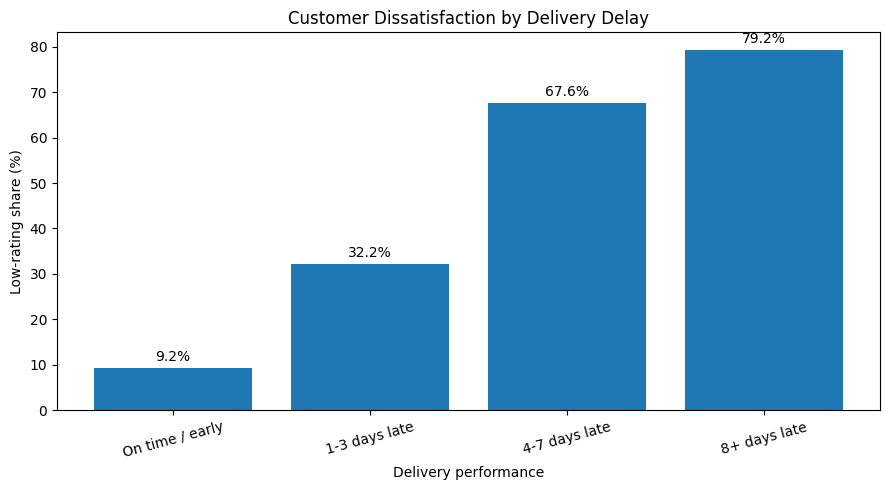

In [6]:

# SECTION 4 — DELIVERY AND CUSTOMER SATISFACTION
# One record per delivered order

# Compare on-time and late deliveries

review_comparison = con.execute("""
    SELECT
        CASE
            WHEN late_flag = 1 THEN 'Late'
            ELSE 'On time / early'
        END AS delivery_group,

        COUNT(*) AS total_orders,

        COUNT(avg_review_score) AS reviewed_orders,

        ROUND(
            COUNT(avg_review_score) * 100.0 /
            COUNT(*), 2
        ) AS review_coverage_pct,

        ROUND(
            AVG(avg_review_score), 2
        ) AS avg_rating,

        ROUND(
            AVG(
                CASE
                    WHEN avg_review_score IS NULL
                        THEN NULL
                    WHEN avg_review_score <= 2
                        THEN 1.0
                    ELSE 0.0
                END
            ) * 100, 2
        ) AS low_rating_pct

    FROM delivery_fact

    GROUP BY 1
    ORDER BY delivery_group
""").df()

print("CUSTOMER SATISFACTION BY DELIVERY STATUS")
display(review_comparison)


# Evaluate whether longer delays correspond
# to worse customer reviews

delay_analysis = con.execute("""
    WITH delay_groups AS (
        SELECT
            CASE
                WHEN days_vs_promise <= 0
                    THEN 'On time / early'
                WHEN days_vs_promise BETWEEN 1 AND 3
                    THEN '1-3 days late'
                WHEN days_vs_promise BETWEEN 4 AND 7
                    THEN '4-7 days late'
                ELSE '8+ days late'
            END AS delay_category,

            CASE
                WHEN days_vs_promise <= 0 THEN 0
                WHEN days_vs_promise <= 3 THEN 1
                WHEN days_vs_promise <= 7 THEN 2
                ELSE 3
            END AS sort_order,

            avg_review_score

        FROM delivery_fact
    )

    SELECT
        delay_category,
        COUNT(*) AS total_orders,
        COUNT(avg_review_score) AS reviewed_orders,

        ROUND(
            AVG(avg_review_score), 2
        ) AS avg_rating,

        ROUND(
            AVG(
                CASE
                    WHEN avg_review_score IS NULL
                        THEN NULL
                    WHEN avg_review_score <= 2
                        THEN 1.0
                    ELSE 0.0
                END
            ) * 100, 2
        ) AS low_rating_pct

    FROM delay_groups

    GROUP BY delay_category, sort_order
    ORDER BY sort_order
""").df()

print("\nCUSTOMER SATISFACTION BY DELAY SEVERITY")
display(delay_analysis)


# Visualize low-rating share by delay group

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    delay_analysis["delay_category"],
    delay_analysis["low_rating_pct"]
)

ax.bar_label(
    bars,
    fmt="%.1f%%",
    padding=3
)

ax.set_ylabel("Low-rating share (%)")
ax.set_xlabel("Delivery performance")
ax.set_title(
    "Customer Dissatisfaction by Delivery Delay"
)

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


## 5. Regional Delivery Performance and Operational Priorities

PASS: Regional order totals reconciled.

TOP 10 STATES BY LATE-DELIVERY RATE


,customer_state,delivered_orders,late_orders,late_delivery_pct,avg_delivery_days,low_rating_pct
14,MA,717,125.0,17.43,21.51,19.94
11,CE,1279,176.0,13.76,21.20,17.12
6,BA,3256,396.0,12.16,19.28,17.03
1,RJ,12350,1495.0,12.11,15.24,18.29
12,PA,946,106.0,11.21,23.73,17.90
8,ES,1995,214.0,10.73,15.72,13.76
16,PB,517,54.0,10.44,20.39,14.84
15,MS,701,68.0,9.70,15.54,13.30
10,PE,1593,153.0,9.60,18.40,14.82
5,SC,3546,291.0,8.21,14.90,13.02



TOP 10 STATES BY NUMBER OF LATE DELIVERIES


,customer_state,delivered_orders,late_orders,late_delivery_pct,share_of_late_orders_pct
0,SP,40494,1820.0,4.49,27.85
1,RJ,12350,1495.0,12.11,22.88
2,MG,11354,519.0,4.57,7.94
6,BA,3256,396.0,12.16,6.06
3,RS,5344,325.0,6.08,4.97
5,SC,3546,291.0,8.21,4.45
8,ES,1995,214.0,10.73,3.28
4,PR,4923,199.0,4.04,3.05
11,CE,1279,176.0,13.76,2.69
10,PE,1593,153.0,9.60,2.34


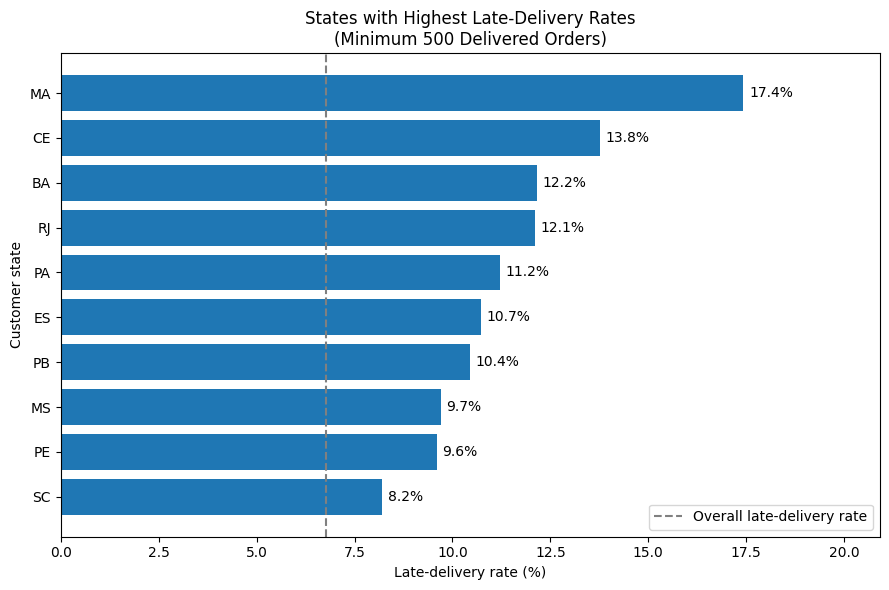

In [7]:

# SECTION 5 — REGIONAL DELIVERY PERFORMANCE
# Customer state is used as the geographic dimension

region_performance = con.execute("""
    SELECT
        customer_state,

        COUNT(*) AS delivered_orders,

        SUM(late_flag) AS late_orders,

        ROUND(
            AVG(late_flag) * 100, 2
        ) AS late_delivery_pct,

        ROUND(
            AVG(delivery_days), 2
        ) AS avg_delivery_days,

        COUNT(avg_review_score) AS reviewed_orders,

        ROUND(
            AVG(avg_review_score), 2
        ) AS avg_rating,

        ROUND(
            AVG(
                CASE
                    WHEN avg_review_score IS NULL THEN NULL
                    WHEN avg_review_score <= 2 THEN 1.0
                    ELSE 0.0
                END
            ) * 100, 2
        ) AS low_rating_pct

    FROM delivery_fact
    GROUP BY customer_state
    ORDER BY delivered_orders DESC
""").df()

# Verify that every analyzed delivery is represented
assert (
    region_performance["delivered_orders"].sum()
    == len(delivery_fact)
)

# Share of all late deliveries attributable to each state
total_late = region_performance["late_orders"].sum()

region_performance["share_of_late_orders_pct"] = (
    region_performance["late_orders"]
    / total_late * 100
).round(2)

# Focus relative-rate comparisons on states
# with at least 500 analyzed deliveries

eligible_regions = region_performance[
    region_performance["delivered_orders"] >= 500
].copy()

print("PASS: Regional order totals reconciled.")

print("\nTOP 10 STATES BY LATE-DELIVERY RATE")
display(
    eligible_regions.nlargest(
        10, "late_delivery_pct"
    )[
        [
            "customer_state",
            "delivered_orders",
            "late_orders",
            "late_delivery_pct",
            "avg_delivery_days",
            "low_rating_pct"
        ]
    ]
)

print("\nTOP 10 STATES BY NUMBER OF LATE DELIVERIES")
display(
    region_performance.nlargest(
        10, "late_orders"
    )[
        [
            "customer_state",
            "delivered_orders",
            "late_orders",
            "late_delivery_pct",
            "share_of_late_orders_pct"
        ]
    ]
)

# Visual: highest late-delivery rates
# among states with >= 500 analyzed orders

chart_data = eligible_regions.nlargest(
    10, "late_delivery_pct"
).sort_values("late_delivery_pct")

fig, ax = plt.subplots(figsize=(9, 6))

bars = ax.barh(
    chart_data["customer_state"],
    chart_data["late_delivery_pct"]
)

ax.bar_label(
    bars,
    fmt="%.1f%%",
    padding=4
)

ax.axvline(
    delivery_fact["late_flag"].mean() * 100,
    linestyle="--",
    color="gray",
    label="Overall late-delivery rate"
)

ax.set_xlabel("Late-delivery rate (%)")
ax.set_ylabel("Customer state")

ax.set_title(
    "States with Highest Late-Delivery Rates\n"
    "(Minimum 500 Delivered Orders)"
)

ax.set_xlim(
    0,
    chart_data["late_delivery_pct"].max() * 1.2
)

ax.legend()
plt.tight_layout()
plt.show()


## 6. Seller Performance and Geographic Risk Adjustment

SELLER ANALYSIS COVERAGE
Single-seller delivered orders: 95,195
Total delivered orders analyzed: 96,470
Sellers with at least 100 delivered orders: 201

TOP 10 SELLERS BY EXCESS LATE DELIVERIES


,seller_id,seller_state,delivered_orders,late_orders,late_delivery_pct,expected_late_pct_for_state_mix,excess_late_orders,avg_rating
1453,4a3ca9315b744ce9f8e9374361493884,SP,1673,168.0,10.04,6.60,57.5,3.91
1,06a2c3af7b3aee5d69171b0e14f0ee87,MA,388,74.0,19.07,7.77,43.9,4.02
4,4869f7a5dfa277a7dca6462dcf3b52b2,SP,1111,118.0,10.62,7.22,37.8,4.18
1564,88460e8ebdecbfecb5f9601833981930,PR,227,42.0,18.50,6.07,28.2,3.52
2,1f50f920176fa81dab994f9023523100,SP,1364,124.0,9.09,7.12,26.9,4.18
1583,8160255418d5aaa7dbdc9f4c64ebda44,SP,355,51.0,14.37,6.85,26.7,4.03
1456,7d13fca15225358621be4086e1eb0964,SP,548,64.0,11.68,7.16,24.7,4.08
1635,e5a3438891c0bfdb9394643f95273d8e,SP,213,34.0,15.96,6.48,20.2,4.02
257,1835b56ce799e6a4dc4eddc053f04066,SP,375,43.0,11.47,6.39,19.0,3.77
59,7c67e1448b00f6e969d365cea6b010ab,SP,963,89.0,9.24,7.28,18.8,3.51



TOP 10 SELLERS BY LATE-ORDER VOLUME


,seller_id,seller_state,delivered_orders,late_orders,late_delivery_pct,expected_late_pct_for_state_mix
1453,4a3ca9315b744ce9f8e9374361493884,SP,1673,168.0,10.04,6.60
2,1f50f920176fa81dab994f9023523100,SP,1364,124.0,9.09,7.12
4,4869f7a5dfa277a7dca6462dcf3b52b2,SP,1111,118.0,10.62,7.22
32,ea8482cd71df3c1969d7b9473ff13abc,SP,1116,96.0,8.60,6.93
1478,6560211a19b47992c3666cc44a7e94c0,SP,1788,95.0,5.31,6.95
59,7c67e1448b00f6e969d365cea6b010ab,SP,963,89.0,9.24,7.28
61,cc419e0650a3c5ba77189a1882b7556a,SP,1646,87.0,5.29,6.98
1467,da8622b14eb17ae2831f4ac5b9dab84a,SP,1272,85.0,6.68,6.10
41,8b321bb669392f5163d04c59e235e066,SP,917,80.0,8.72,7.24
43,955fee9216a65b617aa5c0531780ce60,SP,1252,77.0,6.15,6.32


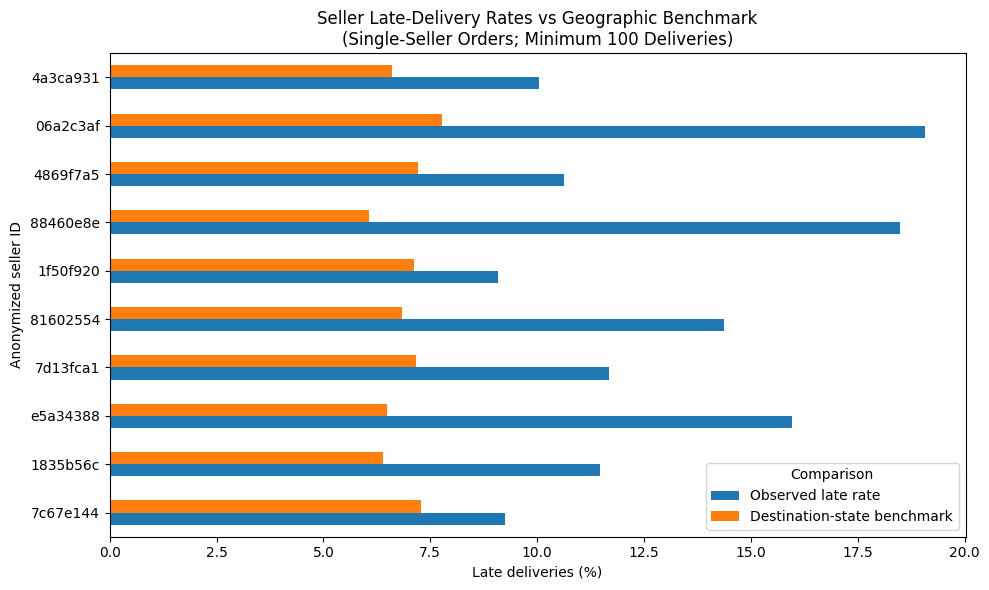

In [8]:

# SECTION 6 — SELLER PERFORMANCE
# Compare observed lateness against customer-state benchmarks

# Load seller reference data
sellers = pd.read_csv(
    BASE_URL + "olist_sellers_dataset.csv"
)

assert sellers["seller_id"].is_unique

con.register("sellers", sellers)

# Build seller-level performance using single-seller orders.
# Multi-seller orders are excluded because a single
# delivery outcome cannot be assigned to one seller.

seller_performance = con.execute("""
    WITH state_baseline AS (
        SELECT
            customer_state,
            AVG(late_flag) AS state_late_rate
        FROM delivery_fact
        GROUP BY customer_state
    ),

    single_seller_orders AS (
        SELECT
            order_id,
            MIN(seller_id) AS seller_id
        FROM order_items
        GROUP BY order_id
        HAVING COUNT(DISTINCT seller_id) = 1
    ),

    seller_deliveries AS (
        SELECT
            d.order_id,
            ss.seller_id,
            s.seller_state,
            d.customer_state,
            d.late_flag,
            d.avg_review_score,
            b.state_late_rate

        FROM delivery_fact d

        INNER JOIN single_seller_orders ss
            ON d.order_id = ss.order_id

        INNER JOIN sellers s
            ON ss.seller_id = s.seller_id

        LEFT JOIN state_baseline b
            ON d.customer_state = b.customer_state
    )

    SELECT
        seller_id,
        seller_state,

        COUNT(*) AS delivered_orders,
        SUM(late_flag) AS late_orders,

        ROUND(
            AVG(late_flag) * 100, 2
        ) AS late_delivery_pct,

        ROUND(
            AVG(state_late_rate) * 100, 2
        ) AS expected_late_pct_for_state_mix,

        ROUND(
            SUM(late_flag) - SUM(state_late_rate), 1
        ) AS excess_late_orders,

        COUNT(avg_review_score) AS reviewed_orders,

        ROUND(
            AVG(avg_review_score), 2
        ) AS avg_rating

    FROM seller_deliveries

    GROUP BY seller_id, seller_state
""").df()

# Avoid ranking low-volume sellers on unstable rates
eligible_sellers = seller_performance[
    seller_performance["delivered_orders"] >= 100
].copy()

print("SELLER ANALYSIS COVERAGE")
print(
    "Single-seller delivered orders:",
    f"{seller_performance['delivered_orders'].sum():,}"
)
print(
    "Total delivered orders analyzed:",
    f"{len(delivery_fact):,}"
)
print(
    "Sellers with at least 100 delivered orders:",
    len(eligible_sellers)
)

# Sellers with more late deliveries than expected
# from the destination-state benchmark

seller_risk = eligible_sellers.nlargest(
    10, "excess_late_orders"
).copy()

print("\nTOP 10 SELLERS BY EXCESS LATE DELIVERIES")
display(
    seller_risk[
        [
            "seller_id",
            "seller_state",
            "delivered_orders",
            "late_orders",
            "late_delivery_pct",
            "expected_late_pct_for_state_mix",
            "excess_late_orders",
            "avg_rating"
        ]
    ]
)

# Sellers accounting for the largest number
# of late orders, regardless of rate

print("\nTOP 10 SELLERS BY LATE-ORDER VOLUME")
display(
    eligible_sellers.nlargest(
        10, "late_orders"
    )[
        [
            "seller_id",
            "seller_state",
            "delivered_orders",
            "late_orders",
            "late_delivery_pct",
            "expected_late_pct_for_state_mix"
        ]
    ]
)

# Visual: observed vs destination-adjusted benchmark

chart_sellers = seller_risk.iloc[::-1].copy()

chart_sellers["seller_short"] = (
    chart_sellers["seller_id"].str[:8]
)

comparison = chart_sellers.set_index("seller_short")[
    [
        "late_delivery_pct",
        "expected_late_pct_for_state_mix"
    ]
].copy()

comparison.columns = [
    "Observed late rate",
    "Destination-state benchmark"
]

ax = comparison.plot.barh(
    figsize=(10, 6)
)

ax.set_title(
    "Seller Late-Delivery Rates vs Geographic Benchmark\n"
    "(Single-Seller Orders; Minimum 100 Deliveries)"
)

ax.set_xlabel("Late deliveries (%)")
ax.set_ylabel("Anonymized seller ID")

ax.legend(title="Comparison")

plt.tight_layout()
plt.show()


## 7. Commercial Performance and Order Economics

PASS: Commercial dataset contains 96,478 unique delivered orders.

MONTHLY COMMERCIAL PERFORMANCE


,month,delivered_orders,merchandise_value_brl,avg_order_merchandise_brl,freight_value_brl,freight_pct_of_merchandise
0,2017-01-01,750,111798.36,149.06,15684.01,14.03
1,2017-02-01,1653,234223.40,141.70,37015.92,15.80
2,2017-03-01,2546,359198.85,141.08,55132.10,15.35
3,2017-04-01,2303,340669.68,147.92,50142.72,14.72
4,2017-05-01,3546,489338.25,138.00,77513.15,15.84
5,2017-06-01,3135,421923.37,134.58,68127.00,16.15
6,2017-07-01,3872,481604.52,124.38,84694.56,17.59
7,2017-08-01,4193,554699.70,132.29,91215.42,16.44
8,2017-09-01,4150,607399.67,146.36,93677.82,15.42
9,2017-10-01,4478,648247.65,144.76,102974.48,15.89



JANUARY-AUGUST YEAR-OVER-YEAR COMPARISON


,year,delivered_orders,merchandise_value_m_brl,avg_order_merchandise_brl,freight_value_brl
0,2017,21998,2.99,136.08,479524.88
1,2018,52783,7.22,136.75,1235993.42



Delivered-order growth: 139.94%
Merchandise-value growth: 141.13%
Average order value growth: 0.49%


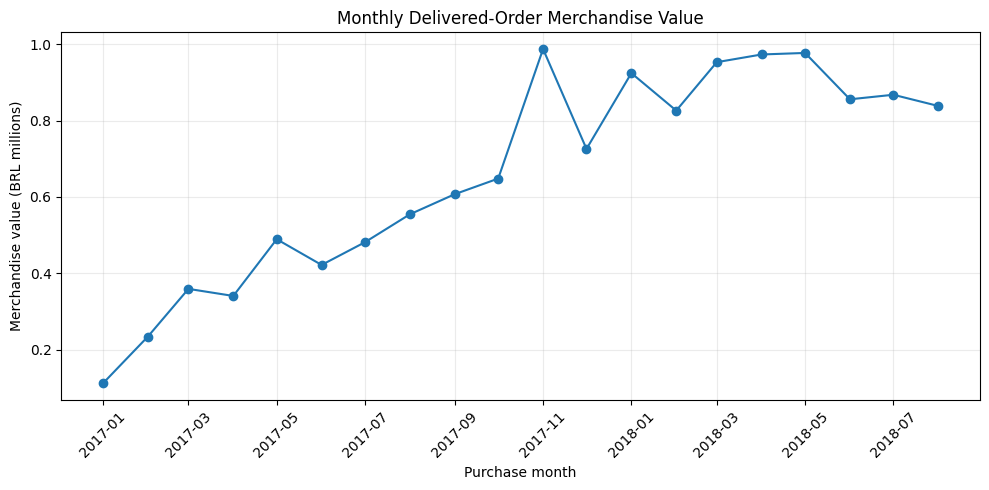

In [9]:

# SECTION 7 — COMMERCIAL PERFORMANCE
# Currency: Brazilian reais (BRL)
# Merchandise value is NOT Olist's recognized revenue.

# Create a delivered-order commercial dataset.
# Retain one row per order to prevent double counting.

commercial_orders = con.execute("""
    SELECT
        order_id,
        customer_unique_id,
        customer_state,

        CAST(
            DATE_TRUNC('month', purchased_at)
            AS DATE
        ) AS order_month,

        merchandise_value_brl,
        freight_value_brl,
        item_count,
        payment_value_brl

    FROM order_fact

    WHERE order_status = 'delivered'
      AND purchased_at IS NOT NULL
      AND merchandise_value_brl IS NOT NULL
""").df()

assert commercial_orders["order_id"].is_unique

assert len(commercial_orders) == (
    order_fact["order_status"] == "delivered"
).sum()

con.register("commercial_orders", commercial_orders)

print(
    "PASS: Commercial dataset contains",
    f"{len(commercial_orders):,}",
    "unique delivered orders."
)


# Monthly performance
# Exclude the sparse initial and ending periods.
# Focus on January 2017 through August 2018.

monthly_commercial = con.execute("""
    SELECT
        order_month AS month,

        COUNT(*) AS delivered_orders,

        ROUND(
            SUM(merchandise_value_brl), 2
        ) AS merchandise_value_brl,

        ROUND(
            AVG(merchandise_value_brl), 2
        ) AS avg_order_merchandise_brl,

        ROUND(
            SUM(freight_value_brl), 2
        ) AS freight_value_brl,

        ROUND(
            SUM(freight_value_brl) * 100.0 /
            NULLIF(SUM(merchandise_value_brl), 0),
            2
        ) AS freight_pct_of_merchandise

    FROM commercial_orders

    WHERE order_month >= DATE '2017-01-01'
      AND order_month < DATE '2018-09-01'

    GROUP BY order_month
    ORDER BY order_month
""").df()

print("\nMONTHLY COMMERCIAL PERFORMANCE")
display(monthly_commercial)


# Compare identical calendar months across years.
# January-August 2017 versus January-August 2018.

yoy_commercial = con.execute("""
    SELECT
        CAST(
            EXTRACT(YEAR FROM order_month)
            AS INTEGER
        ) AS year,

        COUNT(*) AS delivered_orders,

        ROUND(
            SUM(merchandise_value_brl), 2
        ) AS merchandise_value_brl,

        ROUND(
            AVG(merchandise_value_brl), 2
        ) AS avg_order_merchandise_brl,

        ROUND(
            SUM(freight_value_brl), 2
        ) AS freight_value_brl

    FROM commercial_orders

    WHERE EXTRACT(YEAR FROM order_month)
          IN (2017, 2018)
      AND EXTRACT(MONTH FROM order_month)
          BETWEEN 1 AND 8

    GROUP BY 1
    ORDER BY 1
""").df()

# Format value for the executive comparison
yoy_commercial["merchandise_value_m_brl"] = (
    yoy_commercial["merchandise_value_brl"] / 1_000_000
).round(2)

print("\nJANUARY-AUGUST YEAR-OVER-YEAR COMPARISON")
display(
    yoy_commercial[
        [
            "year",
            "delivered_orders",
            "merchandise_value_m_brl",
            "avg_order_merchandise_brl",
            "freight_value_brl"
        ]
    ]
)

# Calculate percentage changes

comparison = yoy_commercial.set_index("year")

order_growth = (
    comparison.loc[2018, "delivered_orders"] /
    comparison.loc[2017, "delivered_orders"] - 1
) * 100

value_growth = (
    comparison.loc[2018, "merchandise_value_brl"] /
    comparison.loc[2017, "merchandise_value_brl"] - 1
) * 100

aov_growth = (
    comparison.loc[2018, "avg_order_merchandise_brl"] /
    comparison.loc[2017, "avg_order_merchandise_brl"] - 1
) * 100

print(f"\nDelivered-order growth: {order_growth:.2f}%")
print(f"Merchandise-value growth: {value_growth:.2f}%")
print(f"Average order value growth: {aov_growth:.2f}%")


# Monthly merchandise-value trend

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    pd.to_datetime(monthly_commercial["month"]),
    monthly_commercial["merchandise_value_brl"] / 1_000_000,
    marker="o"
)

ax.set_title(
    "Monthly Delivered-Order Merchandise Value"
)

ax.set_ylabel("Merchandise value (BRL millions)")
ax.set_xlabel("Purchase month")

ax.grid(alpha=0.25)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## 8. Customer Purchasing Behavior and Repeat Purchase Analysis

CUSTOMER OVERVIEW
Unique customers: 93,358
Delivered orders: 96,478

CUSTOMER PURCHASE FREQUENCY


,purchase_frequency,customers,total_orders,customer_share_pct
0,1 order,90557,90557.0,97.00
1,2 orders,2573,5146.0,2.76
2,3+ orders,228,775.0,0.24



180-DAY OBSERVED REPEAT PURCHASE RATE


,cohort_month,eligible_customers,repeat_customers_180d,repeat_rate_180d_pct
0,2017-01-01,717,32.0,4.46
1,2017-02-01,1628,40.0,2.46
2,2017-03-01,2503,75.0,3.00
3,2017-04-01,2256,63.0,2.79
4,2017-05-01,3451,123.0,3.56
5,2017-06-01,3037,111.0,3.65
6,2017-07-01,3752,124.0,3.30
7,2017-08-01,4057,150.0,3.70
8,2017-09-01,4004,143.0,3.57
9,2017-10-01,4328,117.0,2.70



Overall 180-day repeat rate: 3.11%


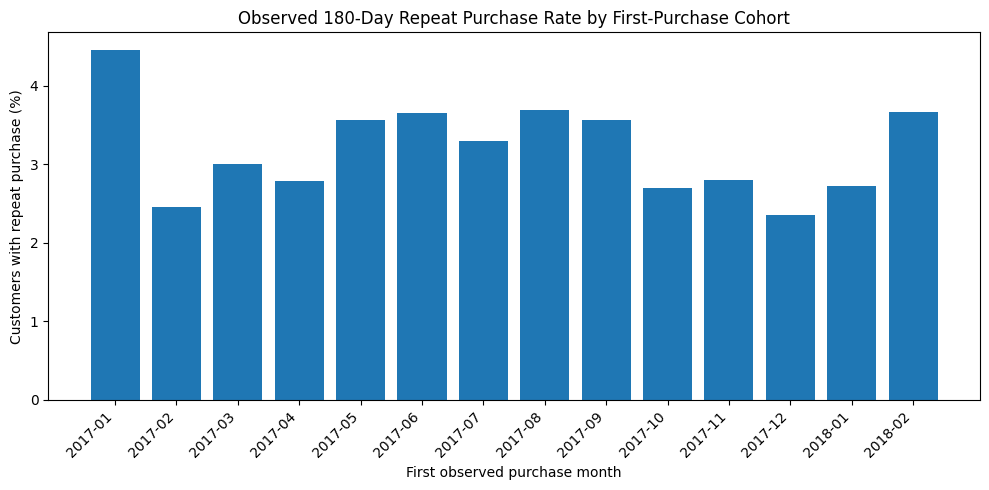

In [10]:

# SECTION 8 — CUSTOMER PURCHASE BEHAVIOR
# Use unique customer identities and delivered orders.

customer_orders = con.execute("""
    SELECT
        order_id,
        customer_unique_id,
        purchased_at,
        merchandise_value_brl,
        freight_value_brl
    FROM order_fact
    WHERE order_status = 'delivered'
      AND purchased_at IS NOT NULL
      AND customer_unique_id IS NOT NULL
""").df()

assert customer_orders["order_id"].is_unique

con.register("customer_orders", customer_orders)

# One record per unique customer

customer_profile = con.execute("""
    SELECT
        customer_unique_id,
        COUNT(*) AS delivered_orders,
        MIN(purchased_at) AS first_purchase,
        MAX(purchased_at) AS last_purchase,
        SUM(merchandise_value_brl) AS total_merchandise_brl
    FROM customer_orders
    GROUP BY customer_unique_id
""").df()

assert (
    customer_profile["delivered_orders"].sum()
    == len(customer_orders)
)

con.register("customer_profile", customer_profile)

print("CUSTOMER OVERVIEW")
print(
    "Unique customers:",
    f"{len(customer_profile):,}"
)
print(
    "Delivered orders:",
    f"{len(customer_orders):,}"
)

# Frequency segmentation

frequency_summary = con.execute("""
    SELECT
        CASE
            WHEN delivered_orders = 1 THEN '1 order'
            WHEN delivered_orders = 2 THEN '2 orders'
            ELSE '3+ orders'
        END AS purchase_frequency,

        COUNT(*) AS customers,

        SUM(delivered_orders) AS total_orders,

        ROUND(
            COUNT(*) * 100.0 /
            (SELECT COUNT(*) FROM customer_profile),
            2
        ) AS customer_share_pct,

        MIN(delivered_orders) AS sort_order

    FROM customer_profile
    GROUP BY 1
    ORDER BY sort_order
""").df()

print("\nCUSTOMER PURCHASE FREQUENCY")
display(
    frequency_summary.drop(columns="sort_order")
)


# Measure repeat purchasing within 180 days.
# Cohorts end in February 2018 so customers
# have a full 180-day observation window
# before the end of August 2018.

cohort_repeat = con.execute("""
    WITH sequenced AS (
        SELECT
            customer_unique_id,
            order_id,
            purchased_at,

            ROW_NUMBER() OVER (
                PARTITION BY customer_unique_id
                ORDER BY purchased_at, order_id
            ) AS purchase_number,

            MIN(purchased_at) OVER (
                PARTITION BY customer_unique_id
            ) AS first_purchase

        FROM customer_orders
    ),

    eligible_customers AS (
        SELECT
            customer_unique_id,

            CAST(
                DATE_TRUNC('month', first_purchase)
                AS DATE
            ) AS cohort_month,

            MAX(
                CASE
                    WHEN purchase_number > 1
                     AND purchased_at <=
                         first_purchase + INTERVAL 180 DAY
                    THEN 1
                    ELSE 0
                END
            ) AS repeated_180d

        FROM sequenced

        WHERE first_purchase >= TIMESTAMP '2017-01-01'
          AND first_purchase < TIMESTAMP '2018-03-01'

        GROUP BY customer_unique_id, cohort_month
    )

    SELECT
        cohort_month,

        COUNT(*) AS eligible_customers,

        SUM(repeated_180d) AS repeat_customers_180d,

        ROUND(
            AVG(repeated_180d) * 100,
            2
        ) AS repeat_rate_180d_pct

    FROM eligible_customers

    GROUP BY cohort_month
    ORDER BY cohort_month
""").df()

print("\n180-DAY OBSERVED REPEAT PURCHASE RATE")
display(cohort_repeat)

# Overall weighted repeat rate across
# all eligible cohorts

overall_repeat_rate = (
    cohort_repeat["repeat_customers_180d"].sum()
    / cohort_repeat["eligible_customers"].sum()
    * 100
)

print(
    f"\nOverall 180-day repeat rate: "
    f"{overall_repeat_rate:.2f}%"
)

# Visualize cohort repeat rates

fig, ax = plt.subplots(figsize=(10, 5))

cohort_labels = (
    pd.to_datetime(cohort_repeat["cohort_month"])
    .dt.strftime("%Y-%m")
)

bars = ax.bar(
    cohort_labels,
    cohort_repeat["repeat_rate_180d_pct"]
)

ax.set_title(
    "Observed 180-Day Repeat Purchase Rate "
    "by First-Purchase Cohort"
)

ax.set_ylabel("Customers with repeat purchase (%)")
ax.set_xlabel("First observed purchase month")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


## 9. Executive Operations Dashboard and Priority Scorecard

*Chart note: monthly delivered-order counts are grouped by purchase month, not by delivery-completion month.*

EXECUTIVE KPI SCORECARD


,KPI,Result
0,Analyzed delivered orders,"96,470"
1,Late-delivery rate,6.77%
2,Average delivery time,12.50 days
3,Low ratings — on-time deliveries,9.23%
4,Low ratings — late deliveries,62.36%
5,Jan-Aug YoY order growth,139.94%
6,Jan-Aug YoY merchandise growth,141.13%
7,180-day observed repeat rate,3.11%


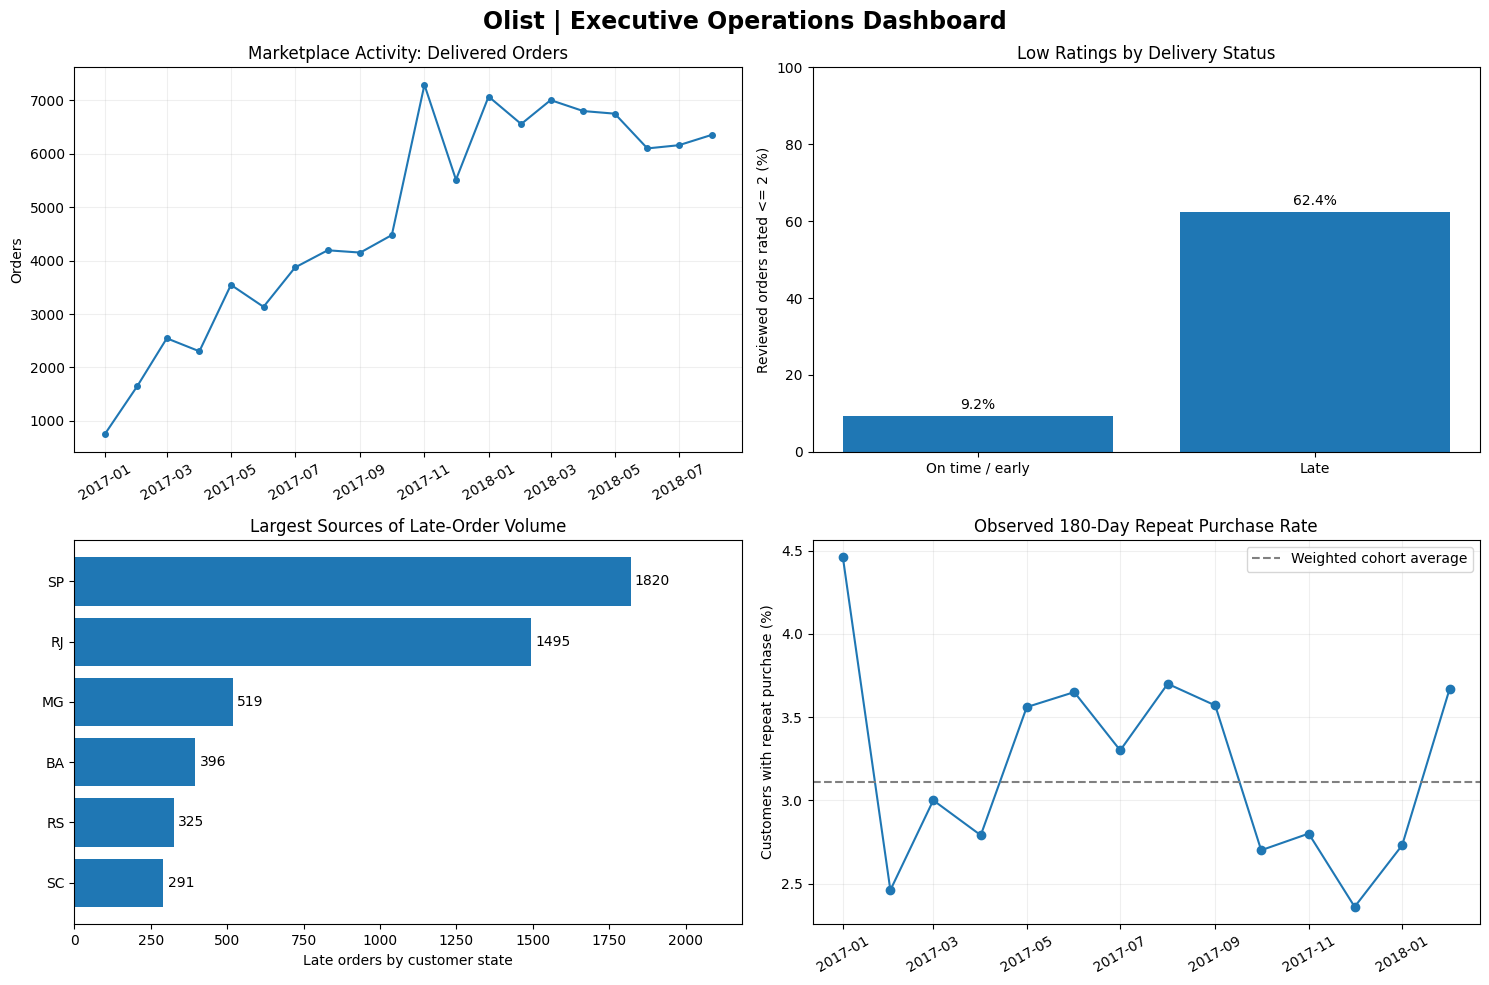


REGIONAL INVESTIGATION CANDIDATES


,customer_state,delivered_orders,late_orders,late_delivery_pct,low_rating_pct
0,SP,40494,1820.0,4.49,10.64
1,RJ,12350,1495.0,12.11,18.29
6,BA,3256,396.0,12.16,17.03
14,MA,717,125.0,17.43,19.94



TOP 3 SELLER INVESTIGATION CANDIDATES


,seller_id,delivered_orders,late_delivery_pct,expected_late_pct_for_state_mix,excess_late_orders
1453,4a3ca9315b744ce9f8e9374361493884,1673,10.04,6.60,57.5
1,06a2c3af7b3aee5d69171b0e14f0ee87,388,19.07,7.77,43.9
4,4869f7a5dfa277a7dca6462dcf3b52b2,1111,10.62,7.22,37.8


In [11]:

# SECTION 9 — EXECUTIVE OPERATIONS DASHBOARD
# All metrics calculated from earlier validated tables.

# Prepare executive KPIs

reviews_indexed = review_comparison.set_index(
    "delivery_group"
)

yoy_indexed = yoy_commercial.set_index("year")

order_growth_pct = (
    yoy_indexed.loc[2018, "delivered_orders"]
    / yoy_indexed.loc[2017, "delivered_orders"] - 1
) * 100

merchandise_growth_pct = (
    yoy_indexed.loc[2018, "merchandise_value_brl"]
    / yoy_indexed.loc[2017, "merchandise_value_brl"] - 1
) * 100

weighted_repeat_rate = (
    cohort_repeat["repeat_customers_180d"].sum()
    / cohort_repeat["eligible_customers"].sum()
) * 100

executive_kpis = pd.DataFrame({
    "KPI": [
        "Analyzed delivered orders",
        "Late-delivery rate",
        "Average delivery time",
        "Low ratings — on-time deliveries",
        "Low ratings — late deliveries",
        "Jan-Aug YoY order growth",
        "Jan-Aug YoY merchandise growth",
        "180-day observed repeat rate"
    ],
    "Result": [
        f"{len(delivery_fact):,}",
        f"{delivery_fact['late_flag'].mean()*100:.2f}%",
        f"{delivery_fact['delivery_days'].mean():.2f} days",
        f"{reviews_indexed.loc['On time / early', 'low_rating_pct']:.2f}%",
        f"{reviews_indexed.loc['Late', 'low_rating_pct']:.2f}%",
        f"{order_growth_pct:.2f}%",
        f"{merchandise_growth_pct:.2f}%",
        f"{weighted_repeat_rate:.2f}%"
    ]
})

print("EXECUTIVE KPI SCORECARD")
display(executive_kpis)


# Build an integrated dashboard

fig, axes = plt.subplots(
    2, 2, figsize=(15, 10)
)

# PANEL 1: Monthly delivered-order volume

monthly_dates = pd.to_datetime(
    monthly_commercial["month"]
)

axes[0, 0].plot(
    monthly_dates,
    monthly_commercial["delivered_orders"],
    marker="o",
    markersize=4
)

axes[0, 0].set_title(
    "Marketplace Activity: Delivered Orders"
)
axes[0, 0].set_ylabel("Orders")
axes[0, 0].tick_params(
    axis="x", rotation=30
)
axes[0, 0].grid(alpha=0.2)


# PANEL 2: Low ratings by delivery status

review_groups = [
    "On time / early",
    "Late"
]

review_values = (
    reviews_indexed.loc[
        review_groups, "low_rating_pct"
    ].values
)

bars = axes[0, 1].bar(
    review_groups, review_values
)

axes[0, 1].bar_label(
    bars, fmt="%.1f%%", padding=3
)

axes[0, 1].set_ylim(0, 100)
axes[0, 1].set_title(
    "Low Ratings by Delivery Status"
)
axes[0, 1].set_ylabel(
    "Reviewed orders rated <= 2 (%)"
)


# PANEL 3: States with most late deliveries

state_chart = (
    region_performance.nlargest(
        6, "late_orders"
    )
    .sort_values("late_orders")
)

bars = axes[1, 0].barh(
    state_chart["customer_state"],
    state_chart["late_orders"]
)

axes[1, 0].bar_label(
    bars, fmt="%.0f", padding=3
)

axes[1, 0].set_xlim(
    0, state_chart["late_orders"].max() * 1.2
)

axes[1, 0].set_title(
    "Largest Sources of Late-Order Volume"
)
axes[1, 0].set_xlabel(
    "Late orders by customer state"
)


# PANEL 4: Observed repeat purchasing

cohort_dates = pd.to_datetime(
    cohort_repeat["cohort_month"]
)

axes[1, 1].plot(
    cohort_dates,
    cohort_repeat["repeat_rate_180d_pct"],
    marker="o"
)

axes[1, 1].axhline(
    weighted_repeat_rate,
    linestyle="--",
    color="gray",
    label="Weighted cohort average"
)

axes[1, 1].set_title(
    "Observed 180-Day Repeat Purchase Rate"
)
axes[1, 1].set_ylabel(
    "Customers with repeat purchase (%)"
)
axes[1, 1].tick_params(
    axis="x", rotation=30
)
axes[1, 1].legend()
axes[1, 1].grid(alpha=0.2)

fig.suptitle(
    "Olist | Executive Operations Dashboard",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


# Priority investigations based on earlier findings

print("\nREGIONAL INVESTIGATION CANDIDATES")

regional_priorities = region_performance[
    region_performance["customer_state"].isin(
        ["RJ", "BA", "MA", "SP"]
    )
].sort_values(
    "late_orders", ascending=False
)

display(
    regional_priorities[
        [
            "customer_state",
            "delivered_orders",
            "late_orders",
            "late_delivery_pct",
            "low_rating_pct"
        ]
    ]
)

print("\nTOP 3 SELLER INVESTIGATION CANDIDATES")

display(
    eligible_sellers.nlargest(
        3, "excess_late_orders"
    )[
        [
            "seller_id",
            "delivered_orders",
            "late_delivery_pct",
            "expected_late_pct_for_state_mix",
            "excess_late_orders"
        ]
    ]
)


## 10. Executive Findings and Operational Action Plan

### Olist Marketplace — Historical Operations Assessment

**To:** Director of Marketplace Operations and Head of Customer Experience  
**From:** Business Analytics  
**Analysis period:** Historical Olist transaction data, 2016–2018  
**Purpose:** Identify evidence-based operational improvement opportunities

### Executive Summary

This analysis of 99,441 marketplace orders identified delivery reliability as a significant customer-experience risk.

Among 96,470 delivered orders with usable timestamps, 6.77% arrived after the estimated delivery date. Late deliveries were associated with substantially worse customer reviews: 62.36% of reviewed late orders received an average rating of two stars or below, compared with 9.23% for on-time deliveries.

Delivery performance also varied geographically. Rio de Janeiro accounted for 22.88% of late deliveries despite representing approximately 12.8% of analyzed deliveries. Several sellers exhibited higher lateness than expected from their customers' destination-state mix.

Meanwhile, January–August delivered-order merchandise value grew 141.13% between 2017 and 2018, driven primarily by a 139.94% increase in order volume rather than higher merchandise value per order.

**Primary recommendation:** Prioritize geographically targeted delivery investigations, validate seller and carrier fulfillment processes, and measure changes in both delivery reliability and customer experience before expanding corrective initiatives.

### Management Priorities

| Priority | Evidence | Recommended action |
|---|---|---|
| 1. Rio de Janeiro | 1,495 late orders; 12.11% late rate | Review fulfillment timing, carrier handoffs and high-delay delivery routes |
| 2. Bahia | 396 late orders; 12.16% late rate | Investigate delivery routes and seller concentrations |
| 3. Seller operations | Selected sellers exceed destination-state lateness benchmarks | Audit dispatch times and fulfillment arrangements, accounting for product and route mix |
| 4. São Paulo | 1,820 late orders; 4.49% late rate | Monitor high-volume operations and identify specific late-delivery concentrations |
| 5. Customer experience | 9.23% low-rating rate even among on-time deliveries | Investigate product quality, communications and other possible dissatisfaction drivers |

### Proposed 90-Day Management Work Plan

**Days 1–30: Diagnose**

- Separate order-processing, seller-dispatch and carrier-transit times.
- Review the highest-delay destinations in RJ and BA.
- Examine the leading seller investigation candidates against comparable sellers, routes and product categories.
- Establish baseline KPIs and confirm data quality.

**Days 31–60: Pilot**

- Test targeted fulfillment or delivery-process improvements in selected routes or seller groups.
- Compare pilot performance with similar non-pilot orders.
- Track delivery reliability, customer ratings, freight economics and operational costs.
- Record implementation costs and potential service trade-offs.

**Days 61–90: Evaluate**

- Determine whether pilot performance improved relative to appropriate comparison groups.
- Assess whether changes are operationally sustainable and financially justified.
- Expand only those interventions that demonstrate credible improvements without unacceptable costs or service trade-offs.

These actions constitute a proposed management framework, not a claim that Olist implemented these initiatives.

### Executive KPI Monitoring Framework

| KPI | Historical baseline | Management use |
|---|---:|---|
| Overall late-delivery rate | 6.77% | Monitor fulfillment reliability |
| Average purchase-to-delivery time | 12.50 days | Monitor service speed |
| RJ late-delivery rate | 12.11% | Evaluate geographic initiatives |
| BA late-delivery rate | 12.16% | Evaluate geographic initiatives |
| Low-rating rate — late deliveries | 62.36% | Monitor experience among affected customers |
| Low-rating rate — on-time deliveries | 9.23% | Identify dissatisfaction beyond delays |
| Observed 180-day repeat purchase rate | 3.11% | Monitor repeat purchasing within comparable cohorts |

Historical baselines are reference points, not validated operational targets. Any proposed numerical targets should be assessed for feasibility and cost.

### Data Needed Before Implementation

The public dataset does not provide complete carrier-level performance, service costs, seller dispatch obligations, customer complaints, refunds or marketplace profitability.

Management would need these additional records before determining specific responsibility, calculating return on investment or approving significant spending.

### Analytical Limitations

- Delivery punctuality is measured against the recorded estimated delivery date, not against an independent service-level standard.
- Missing reviews and delivery timestamps may affect the analyzed sample.
- Regional comparisons identify customer destinations, not necessarily the source of operational delays.
- Seller comparisons adjust for destination-state mix only and cannot establish seller responsibility.
- Observed associations between delays and ratings do not prove causation.
- Merchandise value is not Olist's recognized corporate revenue.
- Repeat-purchase figures reflect only purchases visible within the historical dataset.

### Final Recommendation

**Prioritize a controlled delivery-reliability improvement program centered on RJ and BA, supplemented by seller-level operational reviews and high-volume monitoring in SP.**

Measure outcomes using comparable order cohorts, customer-experience indicators and verified operational costs.

The evidence supports further investigation and targeted pilots. It does not yet justify specific financial-return claims or broad operational restructuring.

---

**Source:** Olist Brazilian E-Commerce Public Dataset, historical anonymized marketplace transactions. Independent portfolio analysis; not an official Olist management report.
